# Dynamics of concentric tube robots
The module `pyctr.cosserat_rod_dynamics` adds inertia to the rod and robot models, so that you can simulate how they move over time. It contains two classes:

- `DynamicCosseratRod`: a single Cosserat rod. It is a port of the example `02_Dynamics/00_Cosserat_Rod_PDE` from [ContinuumRobotExamples](https://github.com/JohnDTill/ContinuumRobotExamples) by John Till.
- `DynamicConcentricTubeRobot`: a concentric tube robot with any number of tubes. It implements the model of J. Till, V. Aloi, K. E. Riojas, P. L. Anderson, R. J. Webster III and C. Rucker, "A Dynamic Model for Concentric Tube Robots", IEEE Transactions on Robotics 36(6), 2020 ([free version](https://pmc.ncbi.nlm.nih.gov/articles/PMC7885994/)).

Both models replace every time derivative with an implicit finite difference (BDF-alpha)

$$x_t \approx c_0\, x + x_h,$$

where the history term $x_h$ contains the values of the previous time steps. With this, every time step is a boundary value problem in the arc length $s$, like the static model. The rod solves it with a shooting method. The robot uses the midpoint rule on all nodes and Newton's method. All values are in SI units.

In this tutorial we simulate a vibrating rod, a robot that is released from a tip force, a robot with a rotating tube, and the snapping of a robot with unstable tube rotation.

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pyctr.cosserat_rod import CurvedCosseratRod
from pyctr.cosserat_rod_dynamics import DynamicCosseratRod, DynamicConcentricTubeRobot
from pyctr.yaml_to_model import load_continous_ctcr_model
%matplotlib inline

## A single rod: vibration of a cantilever
We create a steel rod with a length of 0.5 m. It is clamped at the base and points along z. Besides the usual rod parameters, the constructor takes the time step `dt` and the parameter `bdf_alpha` of the time discretization. The parameter `s` is the distance between the nodes along the rod.

In [2]:
params = {"E": 200e9, "G": 80e9, "r_outer": 1e-3, "rho": 8000, "g": 0, "L": 0.5, "s": 0.0125}
rod = DynamicCosseratRod(params, dt=2e-3, bdf_alpha=-0.2)
rod.set_initial_conditions(np.array([[0, 0, 0]]), np.eye(3))  # base position and orientation

`init_static` solves the static problem and uses the result as the rest state at $t = 0$. Here a force of 0.02 N pulls the tip in x direction. The tip wrench is $[F, M]$ in the world frame.

Then we call `step` without a tip wrench, so the force is released and the rod vibrates. Every call advances the time by `dt`. Both functions return the positions, orientations and internal wrenches at the nodes.

In [3]:
p, R, wrench = rod.init_static([0.02, 0, 0, 0, 0, 0])
shapes = [p]
for i in range(150):
    p, R, wrench = rod.step()  # no tip wrench: the force is released
    shapes.append(p)
shapes = np.array(shapes)  # (time step, node, xyz)
t = np.arange(len(shapes)) * rod.dt

The first bending mode of a cantilever has the period $T_1 = \frac{2\pi}{1.8751^2}\sqrt{\rho A L^4 / (E I)}$. We compare the tip motion with a cosine of this period.

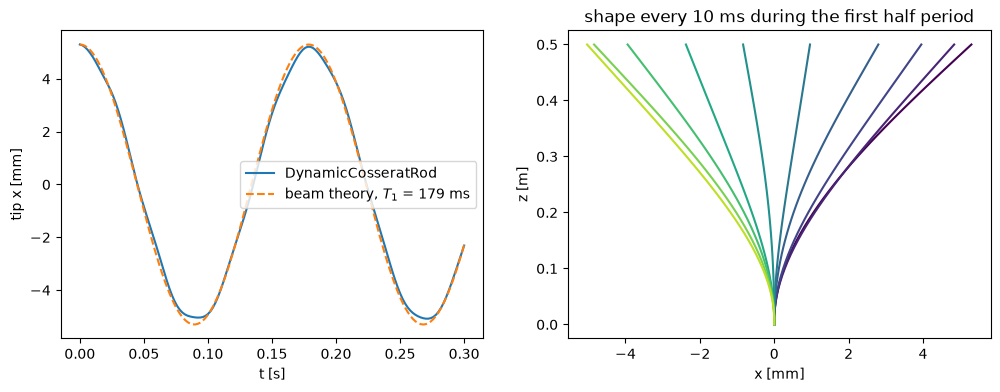

In [4]:
EI, rhoA, L = rod.params["Kbt"][0, 0], rod.params["rho"] * rod.params["A"], rod.params["L"]
T1 = 2 * np.pi / 1.8751**2 * np.sqrt(rhoA * L**4 / EI)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(t, shapes[:, -1, 0] * 1e3, label="DynamicCosseratRod")
ax1.plot(t, shapes[0, -1, 0] * 1e3 * np.cos(2 * np.pi * t / T1), "--", label=f"beam theory, $T_1$ = {T1 * 1e3:.0f} ms")
ax1.set_xlabel("t [s]")
ax1.set_ylabel("tip x [mm]")
ax1.legend()
for i in range(0, 50, 5):
    ax2.plot(shapes[i, :, 0] * 1e3, shapes[i, :, 2], color=plt.cm.viridis(i / 50))
ax2.set_xlabel("x [mm]")
ax2.set_ylabel("z [m]")
ax2.set_title("shape every 10 ms during the first half period")
plt.show()

The amplitude decreases slowly although the rod has no damping. This is numerical damping of the time discretization, and `bdf_alpha` controls it: values close to -0.5 (trapezoidal rule) damp the least, 0 (BDF2) damps the most. Physical damping can be added with the rod parameters `Bse` and `Bbt` (material damping, 3x3 matrices) and `C` (air drag, 3x3 matrix).

## A concentric tube robot from a yaml file
`load_continous_ctcr_model` takes the robot class as second argument. Further keyword arguments go to the constructor of the robot, here the time step.

*Note:* the dynamic results depend directly on the density `rho` in the tube files (here 1140 kg/m³ for nylon). Without gravity (`g: 0`, as in the example) the static shape does not depend on it.

In [5]:
ctr = load_continous_ctcr_model("../../example_robots/ctr_robot.yaml", DynamicConcentricTubeRobot, dt=2e-3)
p_rest, R, wrench = ctr.init_static()
print(f"{len(ctr.s)} nodes, robot length {ctr.s[-1] * 1e3:.0f} mm")

186 nodes, robot length 185 mm


`init_static` uses the current rotations and translations of the tubes, which you set with `rotate` and `translate` as for the static robot class. It returns at every node:

- positions, shape (M, 3)
- orientations of the inner tube, shape (M, 9)
- internal wrenches $[n, m^b]$, shape (M, 6): the force in the world frame and the moment in the frame of the inner tube

`ctr.s` contains the arc length of every node. The full state is in `ctr.y`. Its columns are $p$ (0-2), $R$ (3-11), the velocities $q$ (12-14) and $\omega$ (15-17), $n$ (18-20), $m^b_{xy}$ (21-22), and then for $k$ tubes the torsional moments $m^b_{i,z}$, the angles $\theta_i$ of each tube relative to the inner tube, and their velocities $\gamma_i$ ($k$ columns each).

We define a small function to plot robots. The line is thicker where more tubes overlap.

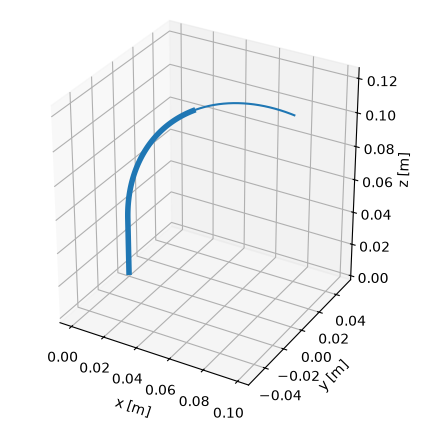

In [6]:
def plot_robot(ax, ctr, p, color="C0", label=None):
    """Backbone of the robot in 3D, thicker where more tubes are present"""
    for i, (_, tube) in enumerate(ctr.tubes):
        n = np.searchsorted(ctr.s, tube.params["L"] * (1 - ctr.betas[i])) + 1
        ax.plot(*p[:n].T, lw=1.5 + 2.5 * i, color=color, label=None if i else label)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_zlabel("z [m]")
    ax.set_aspect("equal")


ax = plt.figure(figsize=(5, 5)).add_subplot(projection="3d")
plot_robot(ax, ctr, p_rest)
plt.show()

## Releasing a tip force
As with the rod, we push the tip with 0.02 N, here in y direction, which is perpendicular to the plane in which the tubes are curved. At $t = 0$ the force is released. This cell takes about 25 s.

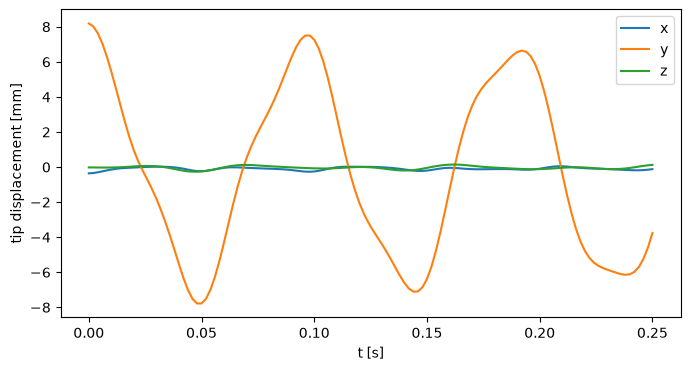

In [7]:
p, R, wrench = ctr.init_static([0, 0.02, 0, 0, 0, 0])
shapes = [p]
for i in range(125):
    p, R, wrench = ctr.step()
    shapes.append(p)
shapes = np.array(shapes)
t = np.arange(len(shapes)) * ctr.dt
tip = (shapes[:, -1] - p_rest[-1]) * 1e3  # tip displacement from the unloaded rest state in mm

plt.figure(figsize=(8, 4))
for j, name in enumerate("xyz"):
    plt.plot(t, tip[:, j], label=name)
plt.xlabel("t [s]")
plt.ylabel("tip displacement [mm]")
plt.legend()
plt.show()

The robot vibrates in y with a period of about 0.09 s. Because the robot is curved, the tip also moves slightly in x and z (less than 0.5 mm).

## Rotating a tube
`rotate` sets the tube angles for the next time step. Here we rotate the outer tube by 90° and then hold it, once fast (within 0.04 s) and once slow (within 0.25 s). For comparison, a second robot computes the static solution for the same angles. This cell takes about 45 s.

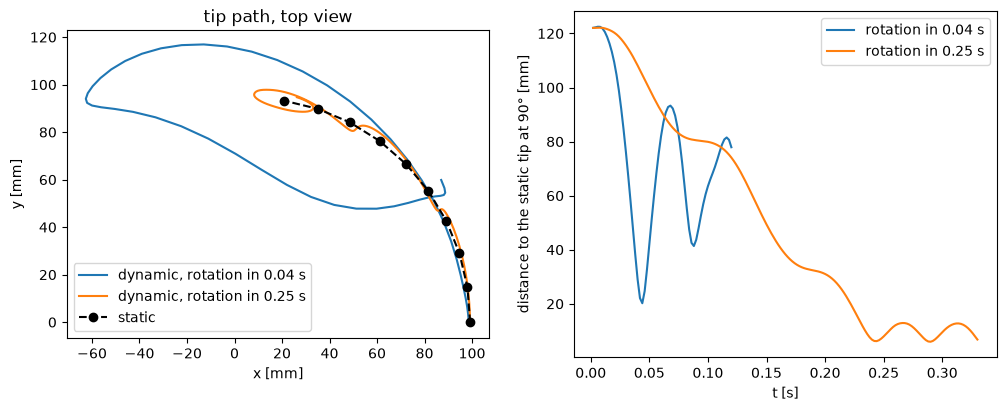

In [8]:
def rotate_outer_tube(ctr, T_ramp, T_end):
    """Rotate the outer tube from 0 to 90 deg within T_ramp, hold until T_end, return times and tip positions"""
    times = np.arange(1, int(T_end / ctr.dt) + 1) * ctr.dt
    ctr.rotate([0, 0])
    ctr.init_static()
    tip = []
    for t in times:
        ctr.rotate([0, np.pi / 2 * min(1, t / T_ramp)])
        tip.append(ctr.step()[0][-1])
    return times, np.array(tip)


static = load_continous_ctcr_model("../../example_robots/ctr_robot.yaml", DynamicConcentricTubeRobot)
static_tip = []
for alpha in np.linspace(0, np.pi / 2, 10):
    static.rotate([0, alpha])
    static_tip.append(static.init_static()[0][-1])
static_tip = np.array(static_tip)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for T_ramp in (0.04, 0.25):
    times, tip = rotate_outer_tube(ctr, T_ramp, T_ramp + 0.08)
    ax1.plot(tip[:, 0] * 1e3, tip[:, 1] * 1e3, label=f"dynamic, rotation in {T_ramp} s")
    ax2.plot(times, np.linalg.norm(tip - static_tip[-1], axis=1) * 1e3, label=f"rotation in {T_ramp} s")
ax1.plot(static_tip[:, 0] * 1e3, static_tip[:, 1] * 1e3, "ko--", label="static")
ax1.set_xlabel("x [mm]")
ax1.set_ylabel("y [mm]")
ax1.set_aspect("equal")
ax1.set_title("tip path, top view")
ax1.legend()
ax2.set_xlabel("t [s]")
ax2.set_ylabel("distance to the static tip at 90° [mm]")
ax2.legend()
plt.show()

The fast rotation is shorter than the vibration period of the robot (about 0.09 s, see above). The tip moves away from the static path, and when the rotation stops it continues to move: the distance to the static solution grows again to more than 90 mm. Without damping, this vibration continues. The slow rotation takes more than two vibration periods: the tip stays close to the static path and vibrates much less at the end.

## Snapping
Two tubes that are curved over their full length become unstable if the outer tube is rotated too far relative to the inner tube: the relative angle at the tip lags behind the angle at the base and then suddenly jumps to a new equilibrium. Without a straight section below the base, this happens when $\sqrt{c}\,L > \pi/2$ with

$$c = \frac{E_1 I_1\, E_2 I_2}{E_1 I_1 + E_2 I_2}\,\kappa_1 \kappa_2 \left(\frac{1}{G_1 J_1} + \frac{1}{G_2 J_2}\right).$$

We build such a robot directly from two `CurvedCosseratRod` tubes of 150 mm length. Torsion is much faster than bending, so we use a shorter time step. This cell takes about 60 s.

In [9]:
nylon = {"E": 339889091.1107947, "G": 97898219.42862949, "rho": 1140, "g": 0}
tubes = [
    CurvedCosseratRod({**nylon, "L": 0.15, "s": 1e-2, "kappa": 11.636, "r_inner": r_in, "r_outer": r_out})
    for r_in, r_out in ((0.5e-3, 1.25e-3), (1.5e-3, 2.5e-3))
]
snap = DynamicConcentricTubeRobot(tubes, dt=2.5e-4)

EI = np.array([tube.params["Kbt"][0, 0] for _, tube in snap.tubes])
GJ = np.array([tube.params["Kbt"][2, 2] for _, tube in snap.tubes])
c = EI.prod() / EI.sum() * 11.636**2 * (1 / GJ).sum()
print(f"sqrt(c) L = {np.sqrt(c) * 0.15:.2f} > pi/2 = {np.pi / 2:.2f}")

sqrt(c) L = 2.30 > pi/2 = 1.57


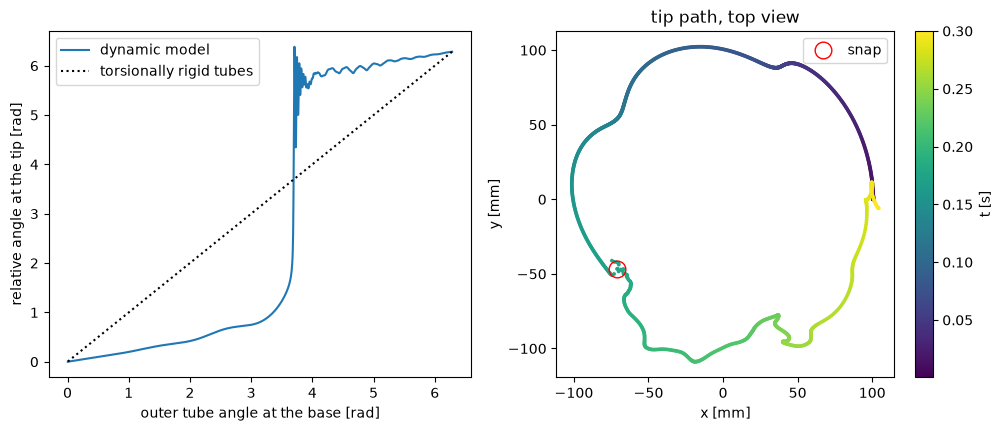

In [10]:
snap.init_static()
k = len(snap.tubes)
alphas = np.linspace(0, 2 * np.pi, 1201)[1:]  # one turn of the outer tube in 0.3 s
theta_tip, tip = [], []
for alpha in alphas:
    snap.rotate([0, alpha])
    p, R, wrench = snap.step()
    theta_tip.append(snap.y[-1, 23 + k + 1])  # angle of the outer tube relative to the inner tube at the tip
    tip.append(p[-1])
tip = np.array(tip)
i_snap = np.argmax(np.abs(np.diff(theta_tip)))  # time step with the largest change of the tip angle

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(alphas, theta_tip, label="dynamic model")
ax1.plot(alphas, alphas, "k:", label="torsionally rigid tubes")
ax1.set_xlabel("outer tube angle at the base [rad]")
ax1.set_ylabel("relative angle at the tip [rad]")
ax1.legend()
points = ax2.scatter(tip[:, 0] * 1e3, tip[:, 1] * 1e3, c=np.arange(1, 1201) * snap.dt, s=3)
fig.colorbar(points, ax=ax2, label="t [s]")
ax2.plot(*tip[i_snap, :2] * 1e3, "o", ms=12, mfc="none", mec="red", label="snap")
ax2.legend()
ax2.set_xlabel("x [mm]")
ax2.set_ylabel("y [mm]")
ax2.set_aspect("equal")
ax2.set_title("tip path, top view")
plt.show()

Until a base angle of about 3.7 rad, the angle at the tip follows with a growing delay. Then the robot snaps: within a few milliseconds the tip angle jumps by more than 4 rad (red circle in the right plot). Afterwards the tubes vibrate in torsion, because the model has no damping. Material damping can be added per tube with the parameter `Bbt` (3x3 matrix, diagonal: bending, bending, torsion), which must be set in the tube parameters before the robot is created.

## Limitations
- The translations (`translate`) cannot change during a simulation, because the model assumes slow insertion. After `translate`, call `init_static` again.
- Not modelled: the tube sections below the base plate (transmission length), friction between the tubes, masses at the tip, and distributed external forces.
- Speed: in Python a time step takes 0.05 s to 0.2 s, depending on the number of nodes.
- `DynamicCosseratRod` uses a shooting method, which fails for very small time steps. `DynamicConcentricTubeRobot` does not have this limitation.